# Word Frequency Analysis: Dickens vs. Poe

## Goals
1. What are the word frequencies in two of Charles Dickens's works?
2. What is the word frequency of Dickens versus Edgar Allan Poe?
3. Are there any words that Dickens or Poe favors compared to the other?

## Ways to Achieve Goals
1. Count the frequency of words in A Tale of Two Cities (https://www.gutenberg.org/ebooks/98) and Great Expectations (https://www.gutenberg.org/ebooks/1400) from Project Gutenberg.
2. Count the words in a Poe collection 
3. Analyze and compare word frequency between the Poe collection and one of the Dickens works from Goals 1 and 2.

## Presentation of Results
The aggregated data would be shown in a chart, likely limited to the top N most frequent words, since raw word counts include many low-value or common terms. Frequencies will be shown as proportions of total words, which is useful for comparing texts of different lengths.


## Setup: fetch and clean the texts

Sources (all Project Gutenberg):
- *A Tale of Two Cities* - Dickens (ebook 98)
- *Great Expectations* - Dickens (ebook 1400)
- *The Works of Edgar Allan Poe, Vol. 1* - Poe (ebook 2147)

Steps
- Download 

In [1]:
import re
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
STOPWORDS = set(stopwords.words('english'))

# Gutenberg wraps every ebook in a license header/footer. These must be removed
START_RE = re.compile(r'\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', re.IGNORECASE | re.DOTALL)
END_RE = re.compile(r'\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', re.IGNORECASE | re.DOTALL)
WORD_RE = re.compile(r"[A-Za-z']+")

BOOKS = {
    'A Tale of Two Cities':  ('98',   'pg98.txt',   'Dickens'),
    'Great Expectations':    ('1400', 'pg1400.txt', 'Dickens'),
    'Works of Poe, Vol. 1':  ('2147', 'pg2147.txt', 'Poe'),
}

def fetch_text(ebook_id, local_fallback):
    url = f'https://www.gutenberg.org/cache/epub/{ebook_id}/pg{ebook_id}.txt'
    try:
        with urllib.request.urlopen(url, timeout=15) as r:
            return r.read().decode('utf-8', errors='replace')
    except Exception:
        with open(local_fallback, encoding='utf-8', errors='replace') as f:
            return f.read()

def strip_boilerplate(text):
    start_m = START_RE.search(text)
    end_m = END_RE.search(text)
    start = start_m.end() if start_m else 0
    end = end_m.start() if end_m else len(text)
    return text[start:end]

def raw_tokens(text):
    # Keep original case for now (needed to spot proper nouns below).
    text = strip_boilerplate(text)
    return [w.strip("'") for w in WORD_RE.findall(text) if len(w) > 1]

raw = {}      # title -> case-preserved tokens
authors = {}  # title -> author
for title, (ebook_id, fallback, author) in BOOKS.items():
    raw[title] = raw_tokens(fetch_text(ebook_id, fallback))
    authors[title] = author
    print(f'{title:24s} {len(raw[title]):>8,} words')

lower_tokens = {title: [t.lower() for t in toks] for title, toks in raw.items()}

# Character/place names (Pip, Havisham, Dupin, ...) would dominate any raw
# word-frequency comparison without actually telling us anything about writing
# style, so flag tokens that are capitalized most of the time they appear and
# exclude them from the content-word counts used below.
def find_proper_nouns(all_tokens, min_count=5, cap_ratio=0.7):
    lower_counts = Counter(t.lower() for t in all_tokens)
    cap_counts = Counter(t.lower() for t in all_tokens if t[0].isupper())
    return {w for w, c in lower_counts.items()
            if c >= min_count and cap_counts.get(w, 0) / c >= cap_ratio}

PROPER_NOUNS = find_proper_nouns([t for toks in raw.values() for t in toks])
print(f'\nFlagged {len(PROPER_NOUNS)} probable proper nouns to exclude, e.g.: '
      f'{sorted(PROPER_NOUNS)[:10]}')

def content_counter(tokens):
    return Counter(t for t in tokens if t not in STOPWORDS and t not in PROPER_NOUNS)

counts = {title: content_counter(toks) for title, toks in lower_tokens.items()}
totals = {title: sum(c.values()) for title, c in counts.items()}
print()
for title, total in totals.items():
    print(f'{title:24s} {total:>8,} content words (stopwords & proper nouns removed)')


A Tale of Two Cities      132,541 words
Great Expectations        176,198 words
Works of Poe, Vol. 1       87,774 words

Flagged 286 probable proper nouns to exclude, e.g.: ['abbaye', 'abel', 'aged', 'ah', 'ainsworth', 'alexandre', 'allan', 'america', 'american', 'andr']

A Tale of Two Cities       59,066 content words (stopwords & proper nouns removed)
Great Expectations         76,558 content words (stopwords & proper nouns removed)
Works of Poe, Vol. 1       41,976 content words (stopwords & proper nouns removed)


## 1 - Word frequencies within Dickens

First as a baseline, I wanted to compare 2 different Dickens novels in terms of word choices. 
This will allow me to better understand the differences between Poe and Dickens as I didn't go as far to grab every single one of their works


Top 15 words, A Tale of Two Cities:
  said         661
  one          441
  would        343
  man          300
  upon         289
  could        282
  little       267
  time         267
  hand         251
  know         231
  two          225
  night        220
  good         217
  like         214
  day          206

Top 15 words, Great Expectations:
  said         1349
  would        599
  one          512
  could        483
  know         391
  time         374
  come         374
  little       371
  upon         366
  like         327
  looked       325
  man          321
  never        315
  old          312
  much         311


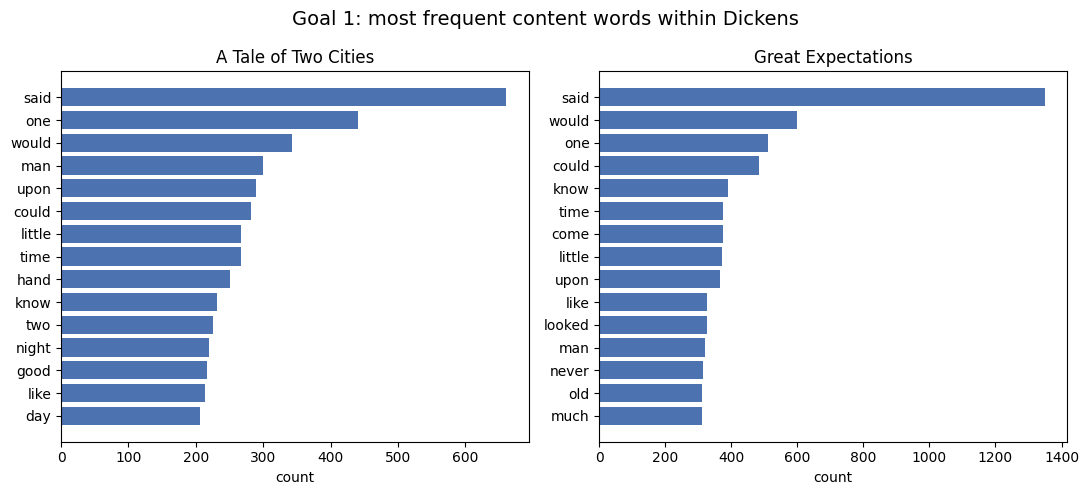

In [2]:
tale_c = counts['A Tale of Two Cities']
great_c = counts['Great Expectations']

print('Top 15 words, A Tale of Two Cities:')
for w, c in tale_c.most_common(15):
    print(f'  {w:12s} {c}')
print('\nTop 15 words, Great Expectations:')
for w, c in great_c.most_common(15):
    print(f'  {w:12s} {c}')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (title, c) in zip(axes, [('A Tale of Two Cities', tale_c), ('Great Expectations', great_c)]):
    top = c.most_common(15)[::-1]
    words, freqs = zip(*top)
    ax.barh(words, freqs, color='#4C72B0')
    ax.set_title(title)
    ax.set_xlabel('count')
fig.suptitle('Goal 1: most frequent content words within Dickens', fontsize=14)
fig.tight_layout()
plt.show()


## 2 - Dickens vs. Poe

The two Dickens books are pooled into one "Dickens" dataset and compare against the Poe dataset. Because the datsets are very different sizes (~136k vs. ~42k content words) everything below is shown as a percentage of each author's own content-word total.


Dickens (both books) content words: 135,624
Poe (Vol. 1) content words:         41,976


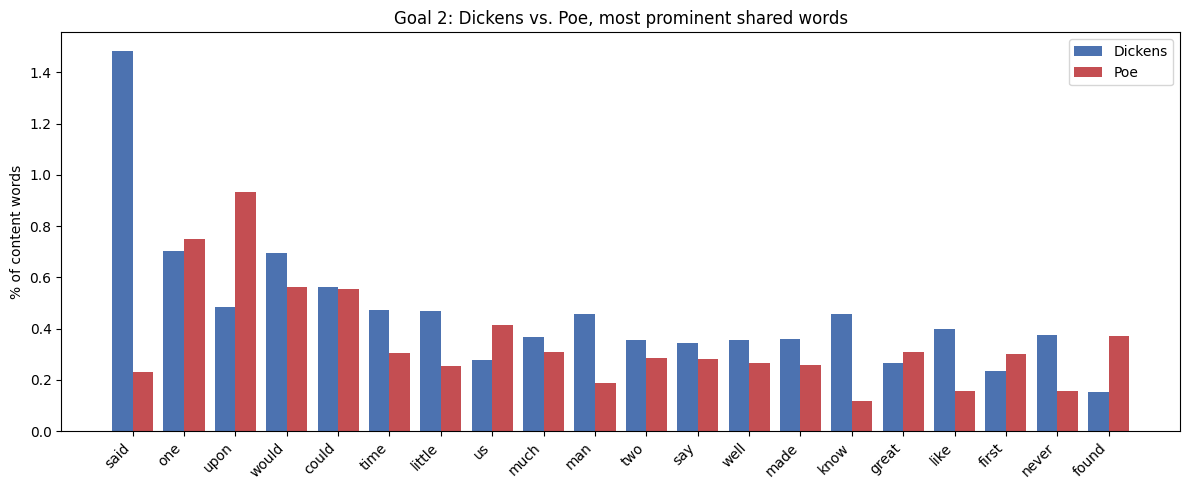

In [4]:
dickens_c = tale_c + great_c
poe_c = counts['Works of Poe, Vol. 1']
dickens_total = sum(dickens_c.values())
poe_total = sum(poe_c.values())

print(f'Dickens (both books) content words: {dickens_total:,}')
print(f'Poe (Vol. 1) content words:         {poe_total:,}')

# Union of each author's top-20 words, ranked by combined share, so the chart
# shows the words that actually matter to at least one of the two authors.
shared_top = sorted(
    set(w for w, _ in dickens_c.most_common(20)) | set(w for w, _ in poe_c.most_common(20)),
    key=lambda w: dickens_c.get(w, 0) / dickens_total + poe_c.get(w, 0) / poe_total,
    reverse=True,
)[:20]

dickens_props = [100 * dickens_c.get(w, 0) / dickens_total for w in shared_top]
poe_props = [100 * poe_c.get(w, 0) / poe_total for w in shared_top]

x = np.arange(len(shared_top))
width = 0.4
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width/2, dickens_props, width, label='Dickens', color='#4C72B0')
ax.bar(x + width/2, poe_props, width, label='Poe', color='#C44E52')
ax.set_xticks(x)
ax.set_xticklabels(shared_top, rotation=45, ha='right')
ax.set_ylabel('% of content words')
ax.set_title('Goal 2: Dickens vs. Poe, most prominent shared words')
ax.legend()
fig.tight_layout()
plt.show()
